<a href="https://colab.research.google.com/github/bogomdanalnur135-coder/NU-/blob/main/SAA_Al_PU_Interfacial_Strength_%E2%80%94_ML_Comparison_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔬 SAA Al/PU Interfacial Strength — ML Comparison Study

**Цель:** Сравнить предсказательную способность ML моделей на:
1. **1000 синтетических строк** (ваш датасет)
2. **Замена первых 16 строк** оригинальными данными из статьи
3. **Только 15 оригинальных строк** из статьи

**Целевая переменная:** SLSS (MPa)

**Входные признаки:**
- Только SAA условия: Concentration (M), Current (A), Time (min)
- + Surface features: Roughness (nm), Contact angle (°)

**Модели:** DT, RF, ET, BG, GB, AB, SVR, KNN (как в статье)


In [1]:
!pip install -q openpyxl scikit-learn pandas numpy matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor, ExtraTreesRegressor,
    BaggingRegressor, GradientBoostingRegressor, AdaBoostRegressor
)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

print('✅ Библиотеки загружены')

✅ Библиотеки загружены


In [3]:
from google.colab import files
import io

print('📁 Загрузите файл dataset_SAA_AlPU_1000.xlsx')
uploaded = files.upload()

filename = list(uploaded.keys())[0]
df_synthetic = pd.read_excel(io.BytesIO(uploaded[filename]))
print(f'✅ Загружено {len(df_synthetic)} строк, колонки: {df_synthetic.columns.tolist()}')
df_synthetic.head()

📁 Загрузите файл dataset_SAA_AlPU_1000.xlsx


Saving dataset_SAA_AlPU_1000.xlsx to dataset_SAA_AlPU_1000 (1).xlsx
✅ Загружено 1000 строк, колонки: ['Sample ID', 'Concentration (M)', 'Current (A)', 'Time (min)', 'Roughness (nm)', 'Contact angle (°)', 'SLSS (MPa)']


,Sample ID,Concentration (M),Current (A),Time (min),Roughness (nm),Contact angle (°),SLSS (MPa)
0,S1,0.7993,1.2763,37.26,136.59,29.52,2.8053
1,S2,1.7211,1.4747,13.95,267.07,79.26,1.6987
2,S3,1.3712,0.6007,48.25,217.13,30.69,2.3892
3,S4,1.1579,1.1998,35.54,131.38,16.06,2.5979
4,S5,0.4496,1.1148,13.20,228.12,23.14,2.7343


In [4]:
# Оригинальные 16 строк из Table 1 статьи (S0–S15)
# S0 = untreated reference
article_data = {
    'Sample ID':          ['S0',  'S1',   'S2',   'S3',   'S4',   'S5',   'S6',  'S7',   'S8',  'S9',    'S10',  'S11',  'S12',  'S13',  'S14',  'S15'],
    'Concentration (M)':  [0,     0.5,    0.5,    0.5,    0.5,    0.2,    1.0,   1.0,    1.0,   1.0,     1.0,    1.8,    1.5,    1.5,    1.5,    1.5],
    'Current (A)':        [0,     0.5,    0.5,    1.5,    1.5,    1.0,    0.2,   1.0,    1.0,   1.0,     1.8,    1.0,    0.5,    0.5,    1.5,    1.5],
    'Time (min)':         [0,     15,     45,     15,     45,     30,     30,    5.5,    30,    54.5,    30,     30,     15,     45,     15,     45],
    'Roughness (nm)':     [100.70,155.73, 181.73, 257.83, 167.23, 255.63, 133.60,200.06, 119.69,175.13,  284.14, 218.58, 191.30, 255.60, 211.73, 239.41],
    'Contact angle (°)':  [101.3, 73.50,  45.17,  24.13,  90.77,  65.80,  88.87, 20.33,  17.77, 69.10,   89.63,  43.80,  48.63,  43.53,  82.73,  29.30],
    'SLSS (MPa)':         [0.32,  2.92,   2.92,   2.58,   3.26,   2.22,   1.65,  2.56,   2.47,  2.66,    2.52,   2.08,   1.84,   2.38,   1.82,   2.25]
}
df_article = pd.DataFrame(article_data)

# Только анодированные (без S0) — как в статье для ML
df_article_15 = df_article[df_article['Sample ID'] != 'S0'].copy().reset_index(drop=True)

print(f'✅ Оригинальные данные статьи: {len(df_article)} строк (включая S0)')
print(f'   Для ML (без S0): {len(df_article_15)} строк')
df_article_15

✅ Оригинальные данные статьи: 16 строк (включая S0)
   Для ML (без S0): 15 строк


,Sample ID,Concentration (M),Current (A),Time (min),Roughness (nm),Contact angle (°),SLSS (MPa)
0,S1,0.5,0.5,15.0,155.73,73.50,2.92
1,S2,0.5,0.5,45.0,181.73,45.17,2.92
2,S3,0.5,1.5,15.0,257.83,24.13,2.58
3,S4,0.5,1.5,45.0,167.23,90.77,3.26
4,S5,0.2,1.0,30.0,255.63,65.80,2.22
5,S6,1.0,0.2,30.0,133.60,88.87,1.65
6,S7,1.0,1.0,5.5,200.06,20.33,2.56
7,S8,1.0,1.0,30.0,119.69,17.77,2.47
8,S9,1.0,1.0,54.5,175.13,69.10,2.66
9,S10,1.0,1.8,30.0,284.14,89.63,2.52


In [5]:
# ──────────────────────────────────────────────────────────────────
# Датасет A: Только синтетические 1000 строк (ваши данные)
# ──────────────────────────────────────────────────────────────────
df_A = df_synthetic.copy()

# ──────────────────────────────────────────────────────────────────
# Датасет B: Заменяем первые 15 строк оригинальными из статьи
# ──────────────────────────────────────────────────────────────────
df_B = df_synthetic.copy()
article_rows = df_article_15[['Concentration (M)', 'Current (A)', 'Time (min)',
                               'Roughness (nm)', 'Contact angle (°)', 'SLSS (MPa)']].copy()
article_rows.insert(0, 'Sample ID', df_article_15['Sample ID'].values)
df_B.iloc[:15] = article_rows.values
# Привести типы
for col in ['Concentration (M)', 'Current (A)', 'Time (min)', 'Roughness (nm)', 'Contact angle (°)', 'SLSS (MPa)']:
    df_B[col] = pd.to_numeric(df_B[col])

# ──────────────────────────────────────────────────────────────────
# Датасет C: Только 15 оригинальных строк из статьи
# ──────────────────────────────────────────────────────────────────
df_C = df_article_15.copy()

print(f'Датасет A (синтетический): {len(df_A)} строк')
print(f'Датасет B (смешанный):     {len(df_B)} строк')
print(f'Датасет C (из статьи):     {len(df_C)} строк')


Датасет A (синтетический): 1000 строк
Датасет B (смешанный):     1000 строк
Датасет C (из статьи):     15 строк


In [6]:
def get_models():
    """Возвращает все 8 моделей как в статье."""
    return {
        'DT':  DecisionTreeRegressor(random_state=42),
        'RF':  RandomForestRegressor(n_estimators=100, random_state=42),
        'ET':  ExtraTreesRegressor(n_estimators=100, random_state=42),
        'BG':  BaggingRegressor(n_estimators=100, random_state=42),
        'GB':  GradientBoostingRegressor(n_estimators=100, max_depth=3,
                                          learning_rate=0.1, random_state=42),
        'AB':  AdaBoostRegressor(n_estimators=50, learning_rate=1, random_state=42),
        'SVR': SVR(kernel='rbf', C=1.0, epsilon=0.1),
        'KNN': KNeighborsRegressor(n_neighbors=5)
    }


def prepare_features(df, feature_set='saa_only'):
    """
    feature_set:
      'saa_only'  → Concentration, Current, Time
      'saa_surf'  → + Roughness, Contact angle
    """
    saa_cols = ['Concentration (M)', 'Current (A)', 'Time (min)']
    surf_cols = ['Roughness (nm)', 'Contact angle (°)']
    target = 'SLSS (MPa)'

    if feature_set == 'saa_only':
        X = df[saa_cols].values
    else:
        X = df[saa_cols + surf_cols].values

    y = df[target].values
    return X, y


def evaluate_models(df, feature_set='saa_only', cv_method='loo'):
    """
    Обучает 8 моделей и считает MAPE и RMSE.
    cv_method: 'loo' для малых датасетов (<100), 'kfold' для больших.
    """
    X, y = prepare_features(df, feature_set)

    # Нормализация MinMax как в статье
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X)

    models = get_models()
    results = {}

    for name, model in models.items():
        if cv_method == 'loo' or len(df) <= 100:
            loo = LeaveOneOut()
            y_pred = cross_val_predict(model, X_scaled, y, cv=loo)
        else:
            from sklearn.model_selection import KFold
            kf = KFold(n_splits=10, shuffle=True, random_state=42)
            y_pred = cross_val_predict(model, X_scaled, y, cv=kf)

        mape = mean_absolute_percentage_error(y, y_pred)
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        results[name] = {'MAPE': round(mape, 4), 'RMSE': round(rmse, 4)}

    return pd.DataFrame(results).T


print('✅ Функции определены')

✅ Функции определены


In [7]:
print('⏳ Обучение на Датасете A (1000 строк, синтетические)...')
res_A_saa = evaluate_models(df_A, feature_set='saa_only')

print('⏳ Обучение на Датасете B (1000 строк, первые 15 заменены)...')
res_B_saa = evaluate_models(df_B, feature_set='saa_only')

print('⏳ Обучение на Датасете C (15 строк из статьи, LOO CV)...')
res_C_saa = evaluate_models(df_C, feature_set='saa_only', cv_method='loo')

print('\n✅ Готово!')


⏳ Обучение на Датасете A (1000 строк, синтетические)...
⏳ Обучение на Датасете B (1000 строк, первые 15 заменены)...
⏳ Обучение на Датасете C (15 строк из статьи, LOO CV)...

✅ Готово!


In [8]:
print('═'*60)
print('ЭКСПЕРИМЕНТ 1: Только SAA условия (Conc, Current, Time)')
print('═'*60)

comparison_saa = pd.DataFrame({
    ('A: Synthetic 1000', 'MAPE'): res_A_saa['MAPE'],
    ('A: Synthetic 1000', 'RMSE'): res_A_saa['RMSE'],
    ('B: Mixed 1000', 'MAPE'):     res_B_saa['MAPE'],
    ('B: Mixed 1000', 'RMSE'):     res_B_saa['RMSE'],
    ('C: Article 15', 'MAPE'):     res_C_saa['MAPE'],
    ('C: Article 15', 'RMSE'):     res_C_saa['RMSE'],
})
comparison_saa.columns = pd.MultiIndex.from_tuples(comparison_saa.columns)
print(comparison_saa.to_string())

print('\n🏆 Лучшая MAPE по каждому датасету (SAA only):')
print(f"  A (Synthetic): {res_A_saa['MAPE'].idxmin()} = {res_A_saa['MAPE'].min():.4f}")
print(f"  B (Mixed):     {res_B_saa['MAPE'].idxmin()} = {res_B_saa['MAPE'].min():.4f}")
print(f"  C (Article):   {res_C_saa['MAPE'].idxmin()} = {res_C_saa['MAPE'].min():.4f}")

════════════════════════════════════════════════════════════
ЭКСПЕРИМЕНТ 1: Только SAA условия (Conc, Current, Time)
════════════════════════════════════════════════════════════
    A: Synthetic 1000         B: Mixed 1000         C: Article 15        
                 MAPE    RMSE          MAPE    RMSE          MAPE    RMSE
DT             0.0198  0.0650        0.0219  0.0784        0.2138  0.6004
RF             0.0120  0.0379        0.0135  0.0514        0.1391  0.4085
ET             0.0090  0.0292        0.0111  0.0475        0.1344  0.4082
BG             0.0120  0.0378        0.0135  0.0513        0.1375  0.4099
GB             0.0109  0.0327        0.0136  0.0497        0.1863  0.5265
AB             0.0338  0.0974        0.0362  0.1067        0.1328  0.4219
SVR            0.0202  0.0555        0.0202  0.0636        0.1787  0.5258
KNN            0.0139  0.0441        0.0158  0.0576        0.1540  0.4433

🏆 Лучшая MAPE по каждому датасету (SAA only):
  A (Synthetic): ET = 0.0090
  B (M

In [9]:
print('⏳ Обучение на Датасете A (1000 строк, + surface features)...')
res_A_surf = evaluate_models(df_A, feature_set='saa_surf')

print('⏳ Обучение на Датасете B (1000 строк, первые 15 заменены, + surface)...')
res_B_surf = evaluate_models(df_B, feature_set='saa_surf')

print('⏳ Обучение на Датасете C (15 строк из статьи, + surface, LOO CV)...')
res_C_surf = evaluate_models(df_C, feature_set='saa_surf', cv_method='loo')

print('\n✅ Готово!')

⏳ Обучение на Датасете A (1000 строк, + surface features)...
⏳ Обучение на Датасете B (1000 строк, первые 15 заменены, + surface)...
⏳ Обучение на Датасете C (15 строк из статьи, + surface, LOO CV)...

✅ Готово!


In [10]:
print('═'*60)
print('ЭКСПЕРИМЕНТ 2: SAA + Surface features (Roughness, CA)')
print('═'*60)

comparison_surf = pd.DataFrame({
    ('A: Synthetic 1000', 'MAPE'): res_A_surf['MAPE'],
    ('A: Synthetic 1000', 'RMSE'): res_A_surf['RMSE'],
    ('B: Mixed 1000', 'MAPE'):     res_B_surf['MAPE'],
    ('B: Mixed 1000', 'RMSE'):     res_B_surf['RMSE'],
    ('C: Article 15', 'MAPE'):     res_C_surf['MAPE'],
    ('C: Article 15', 'RMSE'):     res_C_surf['RMSE'],
})
comparison_surf.columns = pd.MultiIndex.from_tuples(comparison_surf.columns)
print(comparison_surf.to_string())

print('\n🏆 Лучшая MAPE по каждому датасету (SAA + Surface):')
print(f"  A (Synthetic): {res_A_surf['MAPE'].idxmin()} = {res_A_surf['MAPE'].min():.4f}")
print(f"  B (Mixed):     {res_B_surf['MAPE'].idxmin()} = {res_B_surf['MAPE'].min():.4f}")
print(f"  C (Article):   {res_C_surf['MAPE'].idxmin()} = {res_C_surf['MAPE'].min():.4f}")


════════════════════════════════════════════════════════════
ЭКСПЕРИМЕНТ 2: SAA + Surface features (Roughness, CA)
════════════════════════════════════════════════════════════
    A: Synthetic 1000         B: Mixed 1000         C: Article 15        
                 MAPE    RMSE          MAPE    RMSE          MAPE    RMSE
DT             0.0199  0.0642        0.0220  0.0783        0.2283  0.6331
RF             0.0116  0.0368        0.0133  0.0514        0.1588  0.4535
ET             0.0079  0.0254        0.0098  0.0452        0.1368  0.3888
BG             0.0115  0.0367        0.0132  0.0512        0.1601  0.4512
GB             0.0112  0.0341        0.0136  0.0494        0.2014  0.5538
AB             0.0314  0.0913        0.0349  0.1028        0.1947  0.5478
SVR            0.0193  0.0551        0.0199  0.0646        0.1740  0.5013
KNN            0.0139  0.0444        0.0156  0.0575        0.1708  0.4695

🏆 Лучшая MAPE по каждому датасету (SAA + Surface):
  A (Synthetic): ET = 0.0079
  B

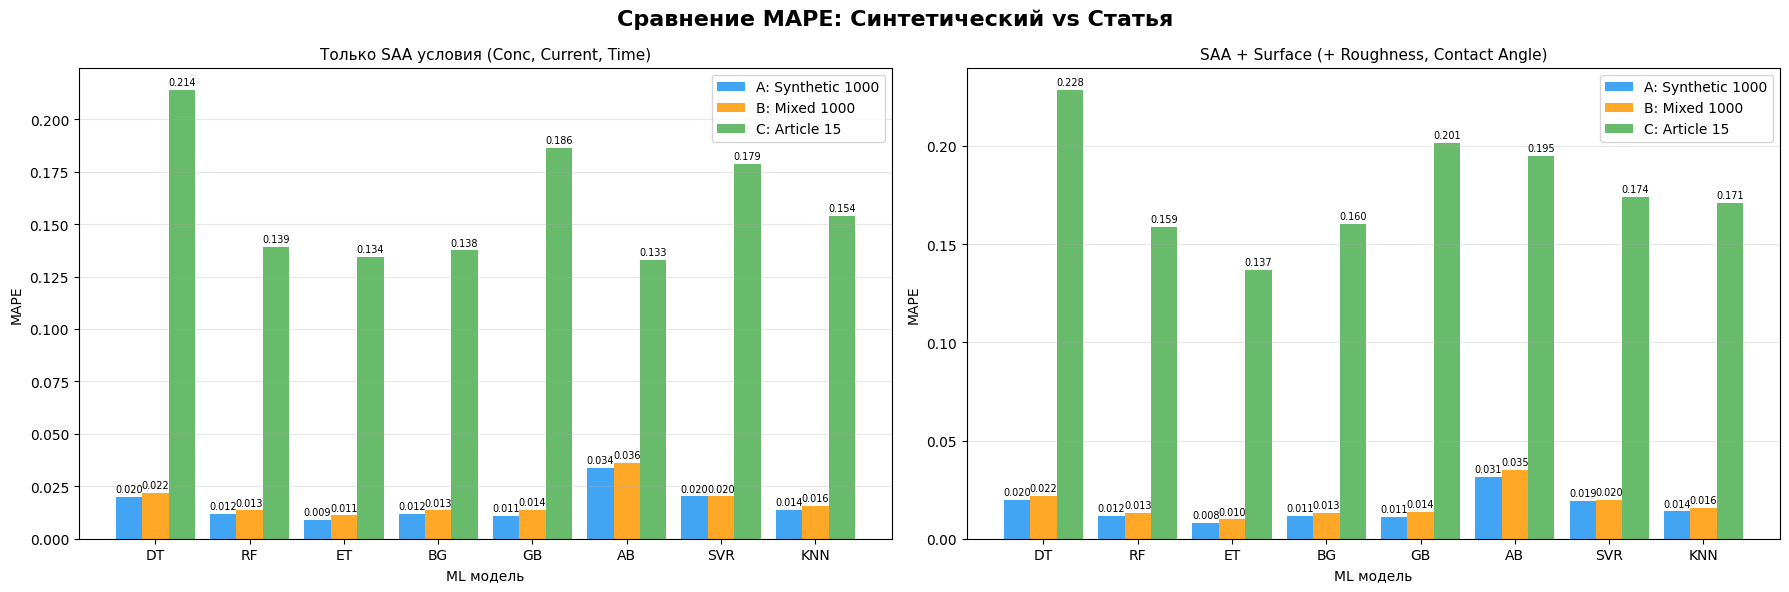

✅ График сохранён как mape_comparison.png


In [11]:
models_list = list(get_models().keys())

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Сравнение MAPE: Синтетический vs Статья', fontsize=16, fontweight='bold')

x = np.arange(len(models_list))
width = 0.28
colors = ['#2196F3', '#FF9800', '#4CAF50']

for ax, (res_A, res_B, res_C, title) in zip(
    axes,
    [
        (res_A_saa, res_B_saa, res_C_saa, 'Только SAA условия (Conc, Current, Time)'),
        (res_A_surf, res_B_surf, res_C_surf, 'SAA + Surface (+ Roughness, Contact Angle)')
    ]
):
    bars_A = ax.bar(x - width, res_A.loc[models_list, 'MAPE'], width,
                    label='A: Synthetic 1000', color=colors[0], alpha=0.85)
    bars_B = ax.bar(x,         res_B.loc[models_list, 'MAPE'], width,
                    label='B: Mixed 1000', color=colors[1], alpha=0.85)
    bars_C = ax.bar(x + width, res_C.loc[models_list, 'MAPE'], width,
                    label='C: Article 15', color=colors[2], alpha=0.85)

    ax.set_title(title, fontsize=11)
    ax.set_xlabel('ML модель')
    ax.set_ylabel('MAPE')
    ax.set_xticks(x)
    ax.set_xticklabels(models_list)
    ax.legend()
    ax.grid(axis='y', alpha=0.3)

    # Добавить значения на бары
    for bar_group in [bars_A, bars_B, bars_C]:
        for bar in bar_group:
            h = bar.get_height()
            ax.annotate(f'{h:.3f}', xy=(bar.get_x() + bar.get_width()/2, h),
                        xytext=(0, 2), textcoords='offset points',
                        ha='center', va='bottom', fontsize=7)

plt.tight_layout()
plt.savefig('mape_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ График сохранён как mape_comparison.png')

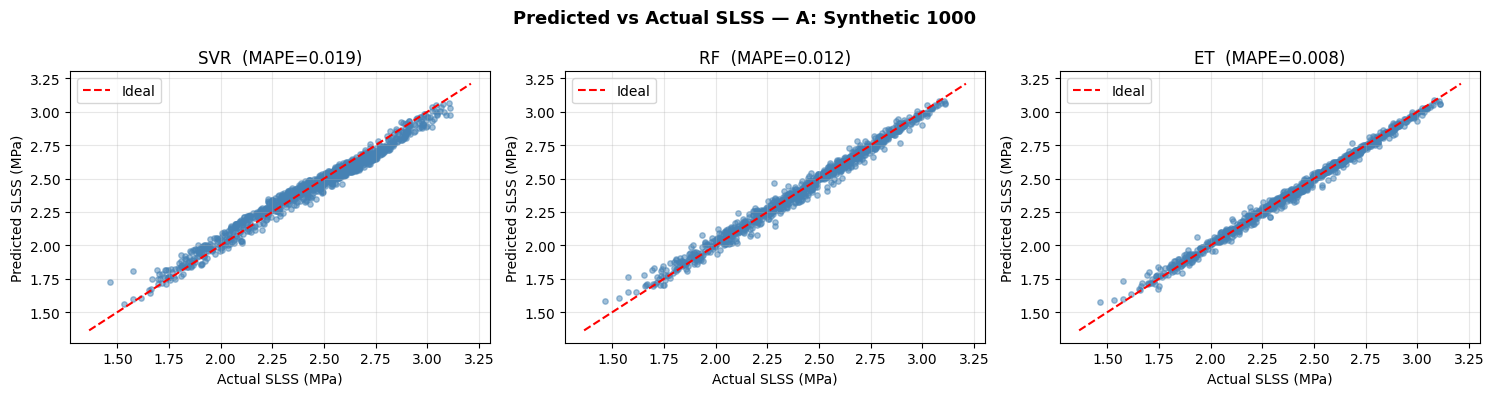

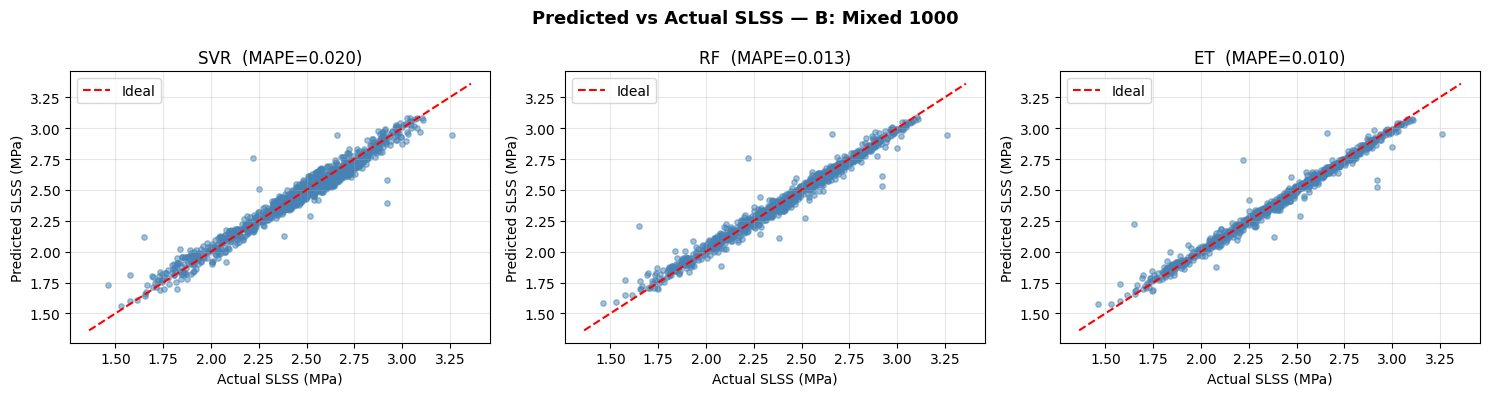

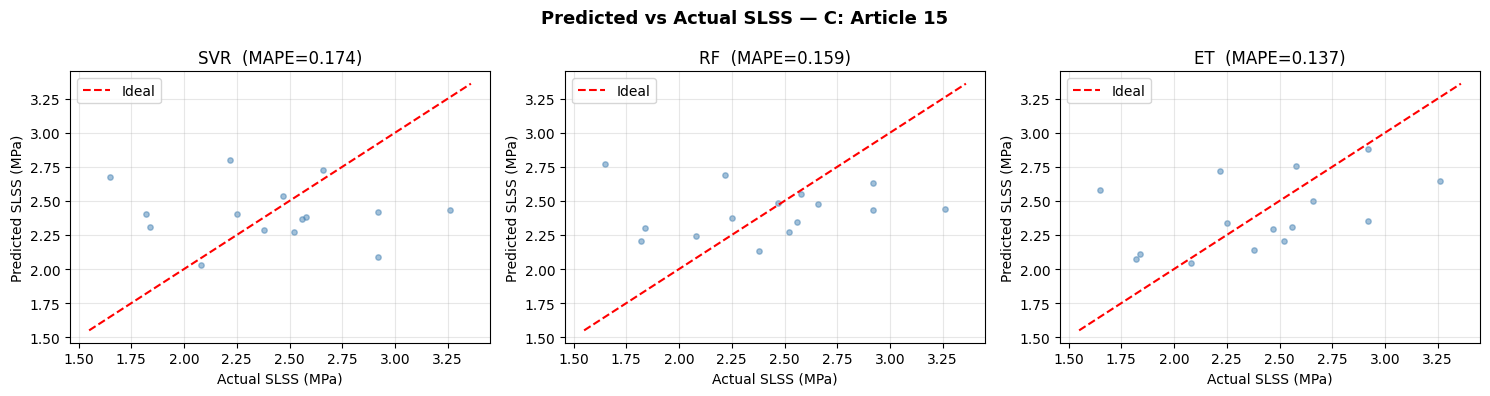

In [12]:
def plot_predicted_vs_actual(df, feature_set, dataset_name, cv_method='loo'):
    """Строит графики предсказанного vs фактического для 3 лучших моделей."""
    X, y = prepare_features(df, feature_set)
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X)

    top3_models = {'SVR': SVR(kernel='rbf'), 'RF': RandomForestRegressor(n_estimators=100, random_state=42),
                   'ET': ExtraTreesRegressor(n_estimators=100, random_state=42)}

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    fig.suptitle(f'Predicted vs Actual SLSS — {dataset_name}', fontsize=13, fontweight='bold')

    for ax, (name, model) in zip(axes, top3_models.items()):
        if cv_method == 'loo' or len(df) <= 100:
            loo = LeaveOneOut()
            y_pred = cross_val_predict(model, X_scaled, y, cv=loo)
        else:
            from sklearn.model_selection import KFold
            kf = KFold(n_splits=10, shuffle=True, random_state=42)
            y_pred = cross_val_predict(model, X_scaled, y, cv=kf)

        mape = mean_absolute_percentage_error(y, y_pred)
        ax.scatter(y, y_pred, alpha=0.5, color='steelblue', s=15)
        lims = [min(y.min(), y_pred.min())-0.1, max(y.max(), y_pred.max())+0.1]
        ax.plot(lims, lims, 'r--', linewidth=1.5, label='Ideal')
        ax.set_xlabel('Actual SLSS (MPa)')
        ax.set_ylabel('Predicted SLSS (MPa)')
        ax.set_title(f'{name}  (MAPE={mape:.3f})')
        ax.legend()
        ax.grid(alpha=0.3)

    plt.tight_layout()
    fname = f'pred_vs_actual_{dataset_name.replace(" ","_")}.png'
    plt.savefig(fname, dpi=120, bbox_inches='tight')
    plt.show()


plot_predicted_vs_actual(df_A, 'saa_surf', 'A: Synthetic 1000')
plot_predicted_vs_actual(df_B, 'saa_surf', 'B: Mixed 1000')
plot_predicted_vs_actual(df_C, 'saa_surf', 'C: Article 15', cv_method='loo')

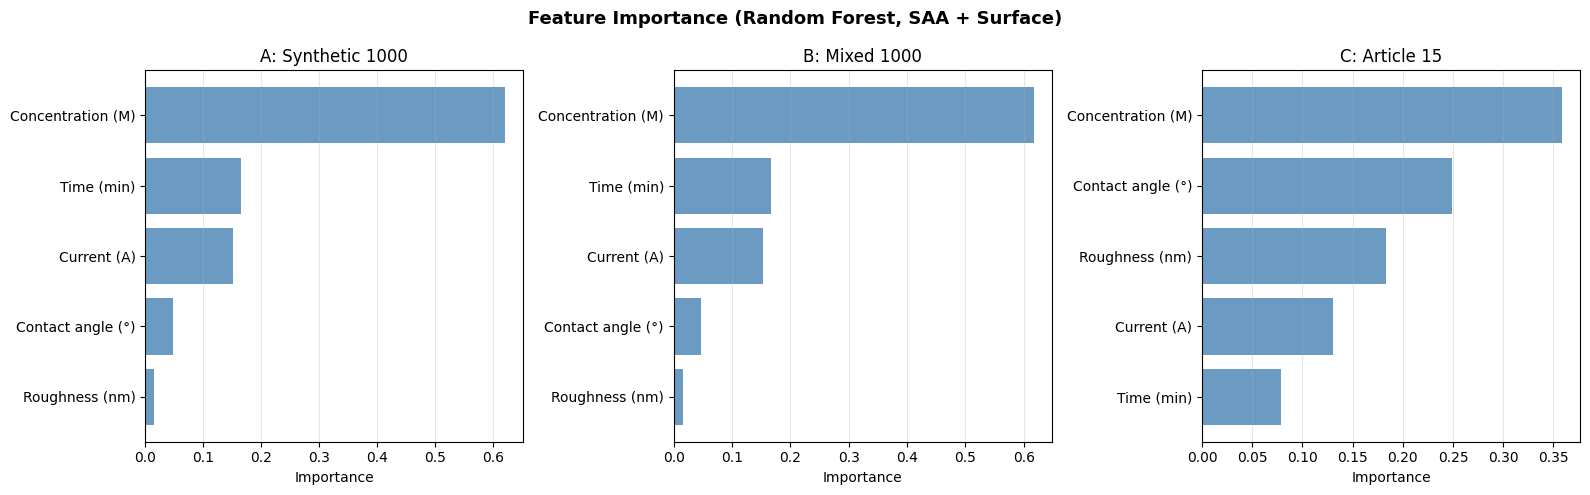

In [13]:
feature_names = ['Concentration (M)', 'Current (A)', 'Time (min)', 'Roughness (nm)', 'Contact angle (°)']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Feature Importance (Random Forest, SAA + Surface)', fontsize=13, fontweight='bold')

for ax, (df, label) in zip(axes, [(df_A, 'A: Synthetic 1000'), (df_B, 'B: Mixed 1000'), (df_C, 'C: Article 15')]):
    X, y = prepare_features(df, 'saa_surf')
    scaler = MinMaxScaler()
    X_sc = scaler.fit_transform(X)
    rf = RandomForestRegressor(n_estimators=200, random_state=42)
    rf.fit(X_sc, y)
    importances = rf.feature_importances_
    sorted_idx = np.argsort(importances)[::-1]

    ax.barh([feature_names[i] for i in sorted_idx[::-1]],
             importances[sorted_idx[::-1]],
             color='steelblue', alpha=0.8)
    ax.set_title(label)
    ax.set_xlabel('Importance')
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()

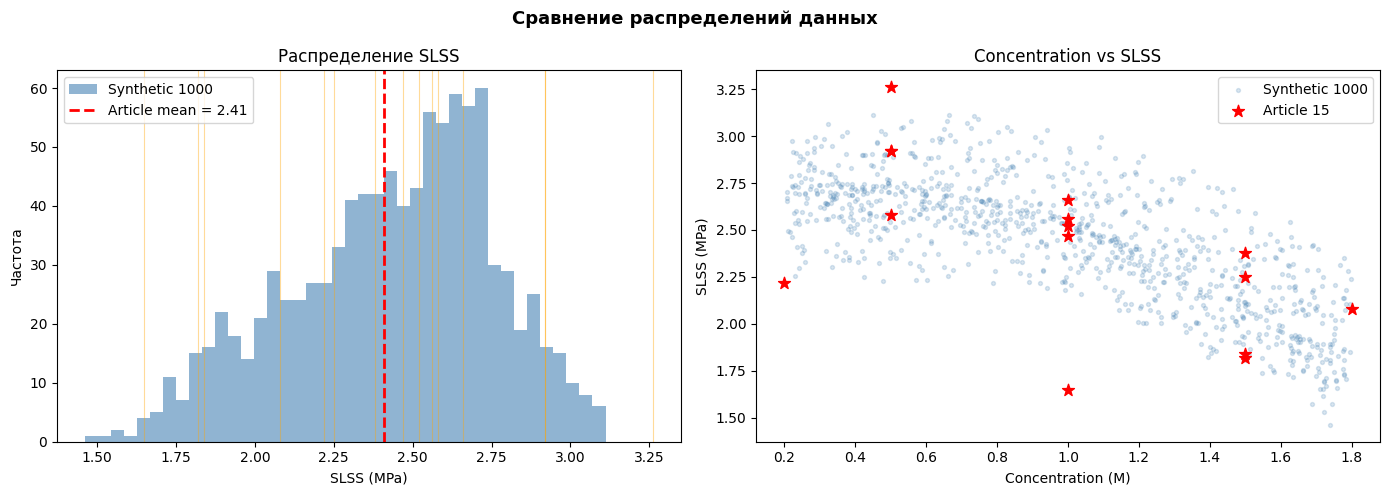

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Сравнение распределений данных', fontsize=13, fontweight='bold')

# SLSS распределение
ax = axes[0]
ax.hist(df_A['SLSS (MPa)'], bins=40, alpha=0.6, label='Synthetic 1000', color='steelblue')
ax.axvline(df_C['SLSS (MPa)'].mean(), color='red', linestyle='--', linewidth=2, label=f'Article mean = {df_C["SLSS (MPa)"].mean():.2f}')
for v in df_C['SLSS (MPa)']:
    ax.axvline(v, color='orange', alpha=0.4, linewidth=0.8)
ax.set_xlabel('SLSS (MPa)')
ax.set_ylabel('Частота')
ax.set_title('Распределение SLSS')
ax.legend()

# Concentration vs SLSS scatter
ax = axes[1]
ax.scatter(df_A['Concentration (M)'], df_A['SLSS (MPa)'], alpha=0.2, s=8, label='Synthetic 1000', color='steelblue')
ax.scatter(df_C['Concentration (M)'], df_C['SLSS (MPa)'], s=80, label='Article 15', color='red', zorder=5, marker='*')
ax.set_xlabel('Concentration (M)')
ax.set_ylabel('SLSS (MPa)')
ax.set_title('Concentration vs SLSS')
ax.legend()

plt.tight_layout()
plt.savefig('distribution_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

In [15]:
print('='*80)
print('ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА — MAPE по всем экспериментам')
print('='*80)

summary = pd.DataFrame({
    'A_SAA_only':  res_A_saa['MAPE'],
    'B_SAA_only':  res_B_saa['MAPE'],
    'C_SAA_only':  res_C_saa['MAPE'],
    'A_SAA+Surf':  res_A_surf['MAPE'],
    'B_SAA+Surf':  res_B_surf['MAPE'],
    'C_SAA+Surf':  res_C_surf['MAPE'],
})
summary.index.name = 'Model'
print(summary.round(4).to_string())

print('\n' + '-'*80)
print('ИНТЕРПРЕТАЦИЯ:')
print('-'*80)

# Сравнение A vs C (SAA only)
diff_AC = (summary['C_SAA_only'] - summary['A_SAA_only']) / summary['A_SAA_only'] * 100
print('\nИзменение MAPE: C (15 статья) vs A (1000 синтетических), SAA only:')
for model in models_list:
    d = diff_AC[model]
    direction = '↑ хуже' if d > 0 else '↓ лучше'
    print(f'  {model:4s}: {d:+.1f}% {direction}')

print('\n💡 Выводы:')
best_A = summary['A_SAA_only'].idxmin()
best_C = summary['C_SAA_only'].idxmin()
print(f'  Лучшая модель на 1000 синтетических: {best_A} (MAPE={summary.loc[best_A,"A_SAA_only"]:.4f})')
print(f'  Лучшая модель на 15 из статьи:       {best_C} (MAPE={summary.loc[best_C,"C_SAA_only"]:.4f})')
print(f'  Статья SVR MAPE (из публикации):     ≈0.1100')

ИТОГОВАЯ СВОДНАЯ ТАБЛИЦА — MAPE по всем экспериментам
       A_SAA_only  B_SAA_only  C_SAA_only  A_SAA+Surf  B_SAA+Surf  C_SAA+Surf
Model                                                                        
DT         0.0198      0.0219      0.2138      0.0199      0.0220      0.2283
RF         0.0120      0.0135      0.1391      0.0116      0.0133      0.1588
ET         0.0090      0.0111      0.1344      0.0079      0.0098      0.1368
BG         0.0120      0.0135      0.1375      0.0115      0.0132      0.1601
GB         0.0109      0.0136      0.1863      0.0112      0.0136      0.2014
AB         0.0338      0.0362      0.1328      0.0314      0.0349      0.1947
SVR        0.0202      0.0202      0.1787      0.0193      0.0199      0.1740
KNN        0.0139      0.0158      0.1540      0.0139      0.0156      0.1708

--------------------------------------------------------------------------------
ИНТЕРПРЕТАЦИЯ:
---------------------------------------------------------------------

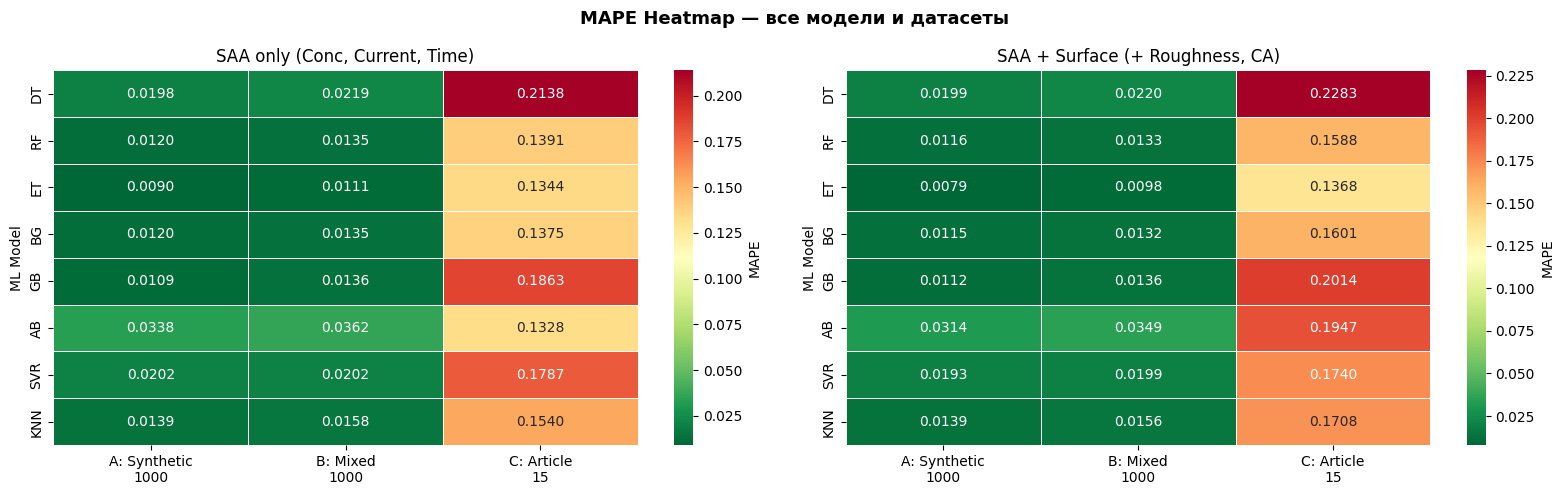

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('MAPE Heatmap — все модели и датасеты', fontsize=13, fontweight='bold')

heat_saa = pd.DataFrame({
    'A: Synthetic\n1000': res_A_saa['MAPE'],
    'B: Mixed\n1000':     res_B_saa['MAPE'],
    'C: Article\n15':     res_C_saa['MAPE'],
})

heat_surf = pd.DataFrame({
    'A: Synthetic\n1000': res_A_surf['MAPE'],
    'B: Mixed\n1000':     res_B_surf['MAPE'],
    'C: Article\n15':     res_C_surf['MAPE'],
})

for ax, heat, title in zip(axes,
    [heat_saa, heat_surf],
    ['SAA only (Conc, Current, Time)', 'SAA + Surface (+ Roughness, CA)']):

    sns.heatmap(heat, annot=True, fmt='.4f', cmap='RdYlGn_r',
                ax=ax, linewidths=0.5, cbar_kws={'label': 'MAPE'})
    ax.set_title(title)
    ax.set_ylabel('ML Model')

plt.tight_layout()
plt.savefig('mape_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

In [17]:
output_file = 'ML_Comparison_Results.xlsx'

with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    # Лист 1: SAA only
    df_saa_out = pd.DataFrame({
        'Model': models_list,
        'A_Synthetic_MAPE': res_A_saa['MAPE'].values,
        'A_Synthetic_RMSE': res_A_saa['RMSE'].values,
        'B_Mixed_MAPE':     res_B_saa['MAPE'].values,
        'B_Mixed_RMSE':     res_B_saa['RMSE'].values,
        'C_Article_MAPE':   res_C_saa['MAPE'].values,
        'C_Article_RMSE':   res_C_saa['RMSE'].values,
    })
    df_saa_out.to_excel(writer, sheet_name='SAA_only', index=False)

    # Лист 2: SAA + Surface
    df_surf_out = pd.DataFrame({
        'Model': models_list,
        'A_Synthetic_MAPE': res_A_surf['MAPE'].values,
        'A_Synthetic_RMSE': res_A_surf['RMSE'].values,
        'B_Mixed_MAPE':     res_B_surf['MAPE'].values,
        'B_Mixed_RMSE':     res_B_surf['RMSE'].values,
        'C_Article_MAPE':   res_C_surf['MAPE'].values,
        'C_Article_RMSE':   res_C_surf['RMSE'].values,
    })
    df_surf_out.to_excel(writer, sheet_name='SAA_plus_Surface', index=False)

    # Лист 3: Сводка
    summary.to_excel(writer, sheet_name='Summary_MAPE')

    # Лист 4: Данные из статьи
    df_article_15.to_excel(writer, sheet_name='Article_15_rows', index=False)

print(f'✅ Результаты сохранены в {output_file}')

# Скачать файл из Colab
from google.colab import files
files.download(output_file)

# Также скачать графики
for fname in ['mape_comparison.png', 'feature_importance.png', 'mape_heatmap.png', 'distribution_comparison.png']:
    try:
        files.download(fname)
    except:
        pass

✅ Результаты сохранены в ML_Comparison_Results.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 📝 Что означают результаты?

| Датасет | Размер | CV метод | Цель |
|---------|--------|----------|------|
| **A: Synthetic** | 1000 строк | 10-fold | Ваши сгенерированные данные |
| **B: Mixed** | 1000 строк | 10-fold | Первые 15 заменены оригиналами |
| **C: Article** | 15 строк | LOO CV | Как в статье |

**Интерпретация MAPE:**
- `MAPE < 0.10` → очень хорошо (< 10% ошибка)
- `MAPE ≈ 0.11` → как в статье (SVR, статья)
- `MAPE > 0.20` → слабая модель

**Что сравниваем:**
1. Если MAPE на датасете A намного меньше, чем на C → синтетические данные слишком "простые" (переобучение)
2. Если похожи → ваш датасет хорошо имитирует реальные данные
3. Feature importance покажет, какие признаки важны в каждом датасете


